<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [PySAL Spatial Analysis](https://github.com/Query-farm/vgi-pysal)

Spatial weights, autocorrelation tests, map classification, inequality measures, and spatial regression from PySAL, callable from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-pysal/blob/main/notebooks/03_the_population_defines_inequality.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-pysal/blob/main/notebooks/README.md)

## Removing one observation changes the distribution

How sensitive are distribution summaries to the observation roster? Retrieve the **32-state Mexico teaching dataset** and compare its 1940 and 2000 per-capita GDP columns. Then exclude the state with the highest 2000 value from both years.

Every state receives equal weight. These are distributions of **state per-capita values**, not household incomes, individual inequality or population-weighted national GDP. Normalized shares support a distribution comparison; the notebook does not interpret nominal levels across years or explain historical causes.

### Choose one change

Edit the parameter below, then restart and run all. The saved default and the final experiment use the same source rows.

In [1]:
EXCLUDE_TOP_2000 = False  # Experiment: True

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.50":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.50"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("pysal")
import hashlib
import os
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

theme()
session = connect(globals())
con = session.connection
previous = {name: os.environ.get(name) for name in ["MPLBACKEND", "PYSAL_MODELS_DIR"]}
model_directory = TemporaryDirectory(prefix="pysal-example-models-")
os.environ.update(MPLBACKEND="Agg", PYSAL_MODELS_DIR=model_directory.name)

assert type(EXCLUDE_TOP_2000) is bool
chart_source = "Historical Mexico state teaching data · libpysal bundled dataset · PySAL v0.1.0\nEqual observation weight per state; not household inequality or national per-capita GDP."

### Connect the published worker

The short Git-tag command runs the released worker in an isolated environment. Shared setup retrieves verified example files. Computation uses bundled or explicitly invented data; no external account is needed. The model registry is isolated in a temporary directory and removed at cleanup.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pysal' (
  TYPE vgi,
  LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-pysal@v0.1.0 vgi-pysal'
);

,Success


### Select the roster once for both years

Materialize the worker’s dataset. Choose the highest 2000 value with an explicit ID tie-break, then apply the same inclusion rule to both years. A missing value would remain missing; all known observations and exclusions are counted before aggregation.

In [5]:
%%sql
CREATE TABLE states AS SELECT id,name,pcgdp1940,pcgdp2000 FROM pysal.main.mexico();
CREATE TABLE excluded_candidate AS SELECT id,name,pcgdp2000 FROM states ORDER BY pcgdp2000 DESC,id LIMIT 1;
CREATE TABLE population AS SELECT s.*,NOT({{EXCLUDE_TOP_2000}} AND s.id=e.id) AS included FROM states s CROSS JOIN excluded_candidate e;
CREATE TABLE long_values AS SELECT id,name,included,1940 AS year,pcgdp1940 AS value FROM population
UNION ALL SELECT id,name,included,2000,pcgdp2000 FROM population;
CREATE TABLE samples AS SELECT 'Full roster' AS scenario,* FROM long_values
UNION ALL SELECT 'Selected roster',* FROM long_values WHERE included;

,Count


In [6]:
roster = con.execute(
    "SELECT year,count(*) AS full_count,count(value) AS known_count,count(*) FILTER(WHERE included) AS selected_count FROM long_values GROUP BY year ORDER BY year"
).df()
display(roster)
candidate = con.execute("SELECT * FROM excluded_candidate").df().iloc[0]
assert roster.full_count.eq(32).all() and roster.known_count.eq(32).all()
fingerprint = hashlib.sha256(
    con.execute("SELECT * FROM states ORDER BY id").df().to_json(orient="records").encode()
).hexdigest()
prose(
    f"The common roster contains **32 states** with both values known. The candidate is **{candidate['name']}** (stable ID {candidate.id}); exclusion is **{EXCLUDE_TOP_2000}**. Both years retain **{int(roster.selected_count.iloc[0])}** states. Input fingerprint: `{fingerprint}`."
)

,year,full_count,known_count,selected_count
0,1940,32,32,32
1,2000,32,32,32


The common roster contains **32 states** with both values known. The candidate is **Distrito Federal** (stable ID 10); exclusion is **False**. Both years retain **32** states. Input fingerprint: `4e12b8b8b5cae7e9da36335d4f5e8da7f1ec420d053c42827a3badfecc0d46ea`.

### Measure inequality and reconstruct it independently

Gini uses pairwise absolute differences normalized by the mean. Theil T uses the mean of `(value / mean) × ln(value / mean)`. Neither measure uses spatial adjacency. Compute the worker aggregates once per scenario/year, then reconstruct both in SQL over the same positive values. Filtering NULLs does not make them observed zeros.

In [7]:
%%sql
CREATE TABLE worker_measures AS SELECT scenario,year,count(value) AS n,pysal.main.gini(value) AS gini,pysal.main.theil(value) AS theil
FROM samples GROUP BY scenario,year;
CREATE TABLE normalized AS SELECT *,avg(value) OVER(PARTITION BY scenario,year) AS mean_value FROM samples WHERE value IS NOT NULL;
CREATE TABLE independent_theil AS SELECT scenario,year,avg(value/mean_value*ln(value/mean_value)) AS sql_theil FROM normalized GROUP BY scenario,year;
CREATE TABLE independent_gini AS SELECT a.scenario,a.year,sum(abs(a.value-b.value))/(2*count(*)*avg(a.value)) AS sql_gini
FROM samples a JOIN samples b ON a.scenario=b.scenario AND a.year=b.year GROUP BY a.scenario,a.year;
CREATE TABLE measures AS SELECT w.*,g.sql_gini,t.sql_theil FROM worker_measures w JOIN independent_gini g USING(scenario,year) JOIN independent_theil t USING(scenario,year);

,Count


In [8]:
%%sql metrics <<
SELECT * FROM measures ORDER BY year,scenario;

In [9]:
display(metrics)
selected_measures = metrics[metrics.scenario.eq("Selected roster")].sort_values("year")
change = selected_measures.iloc[-1].gini - selected_measures.iloc[0].gini
prose(
    f"For the selected common roster, Gini changes by **{change:+.4f}** from 1940 to 2000. Both returned measures match their independent SQL reconstructions. The result describes this equal-state-weight sample; it cannot establish a change in household inequality or its causes."
)

,scenario,year,n,gini,theil,sql_gini,sql_theil
0,Full roster,1940,32,0.353724,0.208943,0.353724,0.208943
1,Selected roster,1940,32,0.353724,0.208943,0.353724,0.208943
2,Full roster,2000,32,0.258113,0.106608,0.258113,0.106608
3,Selected roster,2000,32,0.258113,0.106608,0.258113,0.106608


For the selected common roster, Gini changes by **-0.0956** from 1940 to 2000. Both returned measures match their independent SQL reconstructions. The result describes this equal-state-weight sample; it cannot establish a change in household inequality or its causes.

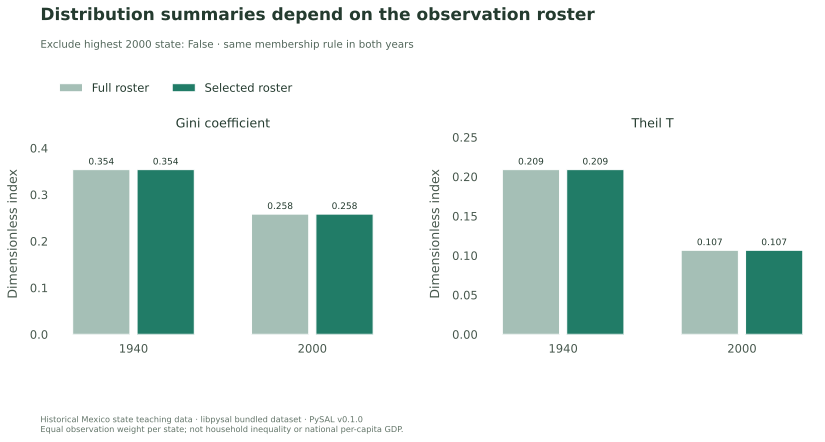

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, field, title in zip(axes, ["gini", "theil"], ["Gini coefficient", "Theil T"], strict=True):
    for offset, scenario, color in [(-0.18, "Full roster", "#A5BFB6"), (0.18, "Selected roster", "#217C67")]:
        group = metrics[metrics.scenario.eq(scenario)].sort_values("year")
        bars = ax.bar(np.arange(2) + offset, group[field], width=0.32, color=color, label=scenario)
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set(
        title=title,
        xticks=[0, 1],
        xticklabels=["1940", "2000"],
        ylabel="Dimensionless index",
        ylim=(0, metrics[field].max() * 1.22),
    )
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.08, 0.83), ncol=2, frameon=False)
finish(
    fig,
    "Distribution summaries depend on the observation roster",
    f"Exclude highest 2000 state: {EXCLUDE_TOP_2000} · same membership rule in both years",
    chart_source,
    name=f"inequality-{EXCLUDE_TOP_2000}",
)

### Inspect the cumulative distribution behind the index

Sort each selected-year distribution by value. The horizontal share counts equally weighted states; the vertical share accumulates the sum of their per-capita values. The equality diagonal would give each state the same value. This is not a population-income Lorenz curve.

In [11]:
%%sql lorenz <<
WITH ranked AS (SELECT *,row_number() OVER(PARTITION BY year ORDER BY value,id) AS position,
count(*) OVER(PARTITION BY year) AS n,sum(value) OVER(PARTITION BY year ORDER BY value,id ROWS UNBOUNDED PRECEDING) AS cumulative_value,
sum(value) OVER(PARTITION BY year) AS total_value FROM samples WHERE scenario='Selected roster')
SELECT year,id,position,n,position::DOUBLE/n AS state_share,cumulative_value/total_value AS value_share FROM ranked ORDER BY year,position;

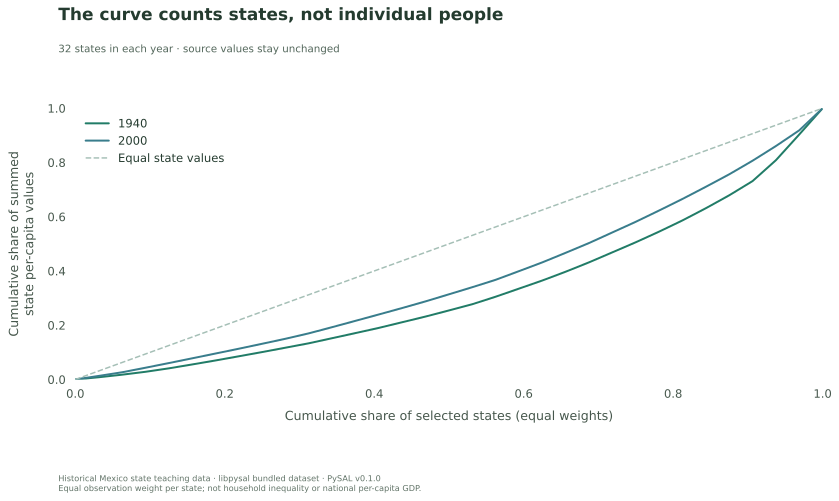

In [12]:
fig, ax = plt.subplots(figsize=(11.8, 7.4))
for year, color in [(1940, "#217C67"), (2000, "#397D8C")]:
    group = lorenz[lorenz.year.eq(year)]
    ax.plot(
        np.r_[0, group.state_share], np.r_[0, group.value_share], color=color, label=str(year), linewidth=2
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="#A5BFB6", label="Equal state values")
ax.set(
    xlabel="Cumulative share of selected states (equal weights)",
    ylabel="Cumulative share of summed\nstate per-capita values",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc="upper left", frameon=False)
finish(
    fig,
    "The curve counts states, not individual people",
    f"{int(roster.selected_count.iloc[0])} states in each year · source values stay unchanged",
    chart_source,
    name=f"lorenz-{EXCLUDE_TOP_2000}",
)

In [13]:
%%sql checks <<
SELECT 'Unique complete state IDs' AS check_name,count(*)=32 AND count(DISTINCT id)=32 AS passed FROM states
UNION ALL SELECT 'All shown values positive and known',count(value)=count(*) AND bool_and(value>0) FROM long_values
UNION ALL SELECT 'One selected roster for both years',count(*)=0 FROM ((SELECT id FROM long_values WHERE year=1940 AND included EXCEPT SELECT id FROM long_values WHERE year=2000 AND included) UNION ALL (SELECT id FROM long_values WHERE year=2000 AND included EXCEPT SELECT id FROM long_values WHERE year=1940 AND included))
UNION ALL SELECT 'Requested exclusion count',count(*) FILTER(WHERE included)=32-{{EXCLUDE_TOP_2000}}::INTEGER FROM population
UNION ALL SELECT 'Gini reconstruction',bool_and(abs(gini-sql_gini)<1e-10) FROM measures
UNION ALL SELECT 'Theil reconstruction',bool_and(abs(theil-sql_theil)<1e-10) FROM measures
UNION ALL SELECT 'Indices finite and nonnegative',bool_and(isfinite(gini) AND isfinite(theil) AND gini>=0 AND gini<=1 AND theil>=0) FROM measures;

In [14]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
for _, group in lorenz.groupby("year"):
    assert abs(group.value_share.iloc[-1] - 1) < 1e-12 and group.value_share.is_monotonic_increasing
prose(f"All **{len(checks)} SQL checks** and both cumulative endpoint/monotonicity checks pass.")

,check_name,passed
0,Unique complete state IDs,True
1,All shown values positive and known,True
2,One selected roster for both years,True
3,Requested exclusion count,True
4,Gini reconstruction,True
5,Theil reconstruction,True
6,Indices finite and nonnegative,True


All **7 SQL checks** and both cumulative endpoint/monotonicity checks pass.

### Experiment: exclude the same state from both years

Change only `EXCLUDE_TOP_2000=False` to **True**. Predict which endpoints remain fixed and which index values can move. Compare the full-roster controls against the selected roster, then inspect the cumulative curves. Selection changes the question; it does not revise source values, explain the historical change or make the result nationally representative.

Source: [libpysal Mexico dataset](https://github.com/pysal/libpysal/tree/v4.15.1/libpysal/examples/mexico), used in Rey and Sastre Gutierrez (2010), *Interregional inequality dynamics in Mexico*.

In [15]:
session.close()
model_directory.cleanup()
for name, value in previous.items():
    if value is None:
        os.environ.pop(name, None)
    else:
        os.environ[name] = value

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-pysal](https://github.com/Query-farm/vgi-pysal)